# Mezcla de probabilidades: Deep Ensemble + Neural Process

**Idea.** En cada instante, cada método da una probabilidad de huso. En vez de usar solo una, se **mezclan las dos** en una sola probabilidad, que después pasa por el postprocesado de siempre (umbral, duración mínima) y la F1 oficial (IoU ≥ 0.2).

**Dos formas de decidir cuánto confiar en cada método**

| | Grilla | Regresión logística (*stacking*) |
|---|---|---|
| Fórmula | p = (1 − w) · p_DE + w · p_NP | p = σ(a · logit p_DE + b · logit p_NP + c) |
| Cómo se elige | Se prueban pesos w de 0 a 1 (de 0.05 en 0.05) y gana el mejor F1 de validación | Un modelo aprende a, b y c con los timesteps de validación (minimiza log-loss) |
| Qué optimiza | El F1 por eventos | Que la probabilidad quede bien calibrada; después se elige el umbral por F1 |
| Variante | Elegir también el umbral | Agregar la MI de cada método, para que el peso cambie según cuánto duda cada uno |

**Protocolo.** Evaluaciones 0, 1 y 2, cinco folds cada una (15 folds). En cada fold, pesos, coeficientes y umbrales se eligen con **validación** y se prueban **una sola vez** en **test**. No se entrena ninguna red: se usan los `.npz` guardados. Código: `src/eeg_uq/probability_mix.py`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

_candidates = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((p for p in _candidates if (p / 'configs' / 'default.yaml').exists()), Path.cwd())
if str(REPO_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / 'src'))
from eeg_uq import probability_mix as pm
from eeg_uq import report

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 250)


def show(figure):
    display(figure)
    plt.close(figure)

REFRESH = False  # True recalcula desde los NPZ (~6 minutos)
results = pm.run_all(refresh=REFRESH)
scores, params, curve = results['scores'], results['params'], results['curve']

## 1. Comparación en test

Δ es la diferencia **pareada** por fold contra el Deep Ensemble solo; *p Wilcoxon* compara esas 15 diferencias con cero. NLL y ECE miden la calibración de la probabilidad mezclada (menor es mejor).

In [2]:
display(pm.summary(scores))

,F1 (%),precisión (%),recall (%),FP,FN,NLL,ECE,Δ F1 (puntos),Δ precisión (puntos),folds que mejoran F1,p Wilcoxon
método,,,,,,,,,,,
Deep Ensemble,83.57 ± 0.85,84.38 ± 3.25,82.98 ± 3.18,166.9,181.8,0.0473,0.0037,0.00,0.00,0/15,NaN
Neural Process,83.34 ± 0.92,85.16 ± 2.75,81.74 ± 2.70,154.3,194.6,0.0551,0.0066,-0.22,0.78,3/15,0.0413
Grilla: peso,83.61 ± 0.88,84.69 ± 3.36,82.76 ± 2.97,162.9,184.0,0.0478,0.0043,0.04,0.31,7/15,0.5509
Grilla: peso + umbral,83.52 ± 0.83,83.64 ± 3.77,83.72 ± 3.96,178.8,174.1,0.0479,0.0042,-0.04,-0.74,5/15,0.5614
Logística: p_DE + p_NP,83.56 ± 0.77,84.09 ± 3.85,83.32 ± 3.64,172.1,178.4,0.0468,0.0026,-0.01,-0.29,6/15,0.8040
Logística: p + MI,83.50 ± 0.89,84.25 ± 3.63,83.03 ± 3.65,169.3,181.5,0.0469,0.0027,-0.07,-0.13,6/15,0.5245


In [3]:
print('F1 por evaluación')
f1 = scores.pivot_table(index=['evaluación', 'fold'], columns='método', values='F1 (%)', sort=False).reset_index()
display(report.by_evaluation(f1, [c for c in f1.columns if c not in ('evaluación', 'fold')]))

F1 por evaluación


,eval 0,eval 1,eval 2,"promedio eval 0, 1 y 2"
método,,,,
Deep Ensemble,83.55 ± 0.91,83.79 ± 0.41,83.35 ± 1.2,83.57 ± 0.85
Neural Process,83.43 ± 0.89,83.29 ± 0.72,83.32 ± 1.3,83.34 ± 0.92
Grilla: peso,83.52 ± 0.99,83.81 ± 0.41,83.5 ± 1.2,83.61 ± 0.88
Grilla: peso + umbral,83.58 ± 1.2,83.73 ± 0.27,83.25 ± 0.83,83.52 ± 0.83
Logística: p_DE + p_NP,83.46 ± 1.1,83.8 ± 0.43,83.41 ± 0.76,83.56 ± 0.77
Logística: p + MI,83.67 ± 1.2,83.72 ± 0.57,83.1 ± 0.83,83.5 ± 0.89


## 2. Grilla: ¿qué peso conviene?

F1 promedio de los 15 folds para cada peso de Neural Process (0 = solo Deep Ensemble, 1 = solo Neural Process), con el umbral fijo en 0.425. A la izquierda, en validación (donde se elige); a la derecha, en test. Debajo, cuántos folds de test mejoran contra el Deep Ensemble solo y qué peso eligió la validación en cada fold.

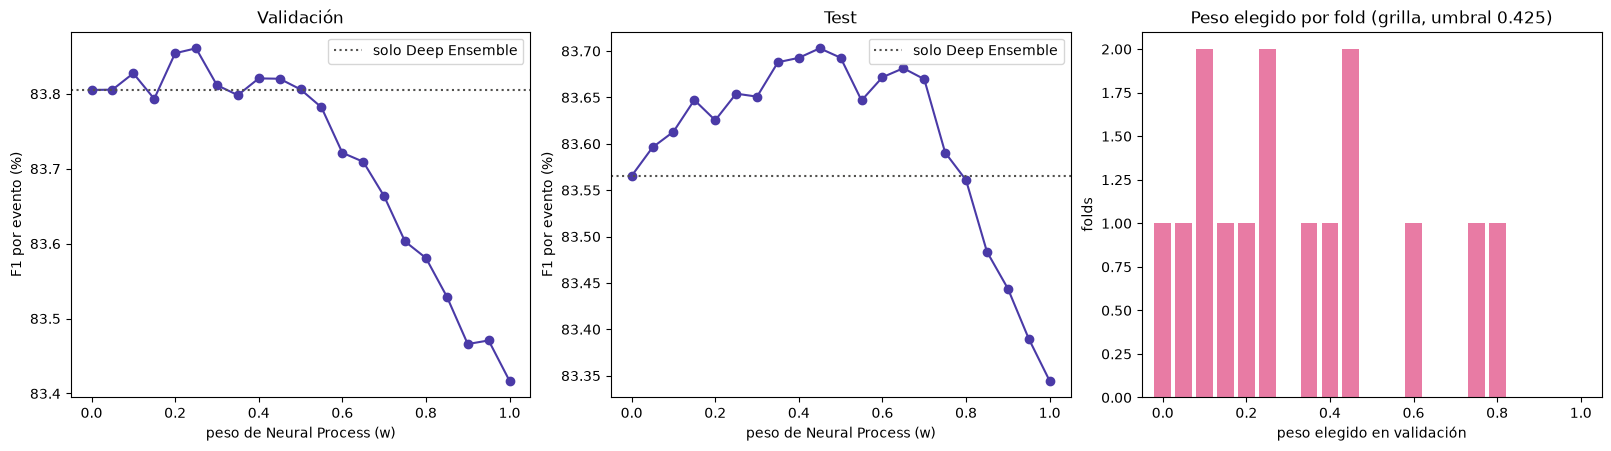

peso NP,0.00,0.05,0.10,0.15,0.20,0.25,0.30,0.35,0.40,0.45,0.50,0.55,0.60,0.65,0.70,0.75,0.80,0.85,0.90,0.95,1.00
F1 val (%),83.81,83.81,83.83,83.79,83.85,83.86,83.81,83.80,83.82,83.82,83.81,83.78,83.72,83.71,83.66,83.60,83.58,83.53,83.47,83.47,83.42
F1 test (%),83.57,83.60,83.61,83.65,83.63,83.65,83.65,83.69,83.69,83.70,83.69,83.65,83.67,83.68,83.67,83.59,83.56,83.48,83.44,83.39,83.34
folds de test que mejoran,0.00,8.00,10.00,11.00,9.00,11.00,10.00,10.00,10.00,9.00,11.00,7.00,8.00,8.00,7.00,6.00,6.00,6.00,5.00,3.00,3.00


In [4]:
mean_curve = curve.groupby('peso NP')[['F1 val (%)', 'F1 test (%)']].mean()
test_by_fold = curve.pivot_table(index=['evaluación', 'fold'], columns='peso NP', values='F1 test (%)')
improves = (test_by_fold.sub(test_by_fold[0.0], axis=0) > 0).sum()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4), constrained_layout=True)
for ax, column, title in ((axes[0], 'F1 val (%)', 'Validación'), (axes[1], 'F1 test (%)', 'Test')):
    ax.plot(mean_curve.index, mean_curve[column], marker='o', color='#4a3aa7')
    ax.axhline(mean_curve[column].iloc[0], color=report.CHANCE, linestyle=':', label='solo Deep Ensemble')
    ax.set_xlabel('peso de Neural Process (w)')
    ax.set_ylabel('F1 por evento (%)')
    ax.set_title(title)
    ax.legend()
axes[2].bar(params['grilla: peso NP'].value_counts().sort_index().index,
            params['grilla: peso NP'].value_counts().sort_index().values, width=0.04, color='#e87ba4')
axes[2].set_xlabel('peso elegido en validación')
axes[2].set_ylabel('folds')
axes[2].set_title('Peso elegido por fold (grilla, umbral 0.425)')
axes[2].set_xlim(-0.05, 1.05)
show(fig)
display(pd.DataFrame({'F1 val (%)': mean_curve['F1 val (%)'], 'F1 test (%)': mean_curve['F1 test (%)'],
                      'folds de test que mejoran': improves}).T.round(2))

## 3. Regresión logística: ¿cuánto confía en cada método?

Coeficientes por fold (media, mediana, mínimo y máximo). En la versión **sin MI**, los coeficientes se leen directo: es el peso que recibe el logit de cada método. En la versión **con MI**, las entradas están estandarizadas: un término *logit × MI* negativo significa que el modelo le baja el peso a esa probabilidad cuando esa MI es alta.

In [5]:
coefs = params[[c for c in params.columns if 'coef' in c or 'intercepto' in c]]
display(coefs.describe().T[['mean', '50%', 'min', 'max']].round(3))
ratio = params['Logística: p_DE + p_NP: coef logit p_NP'] / params['Logística: p_DE + p_NP: coef logit p_DE']
print(f'Peso relativo de Neural Process frente al Deep Ensemble (sin MI): {100 * ratio.mean():.1f}% (rango {100 * ratio.min():.1f}% a {100 * ratio.max():.1f}%)')

,mean,50%,min,max
Logística: p_DE + p_NP: coef logit p_DE,0.850,0.859,0.689,1.009
Logística: p_DE + p_NP: coef logit p_NP,0.060,0.061,-0.027,0.182
Logística: p_DE + p_NP: intercepto,-0.143,-0.171,-0.338,0.150
Logística: p + MI: coef logit p_DE,3.268,3.254,2.823,3.980
Logística: p + MI: coef logit p_NP,0.537,0.381,0.003,1.010
Logística: p + MI: coef log MI_DE,-0.107,-0.114,-0.471,0.289
Logística: p + MI: coef log MI_NP,0.011,0.035,-0.320,0.192
Logística: p + MI: coef logit p_DE × log MI_DE,-0.543,-0.573,-0.816,-0.200
Logística: p + MI: coef logit p_DE × log MI_NP,-0.125,-0.150,-0.408,0.400
Logística: p + MI: coef logit p_NP × log MI_DE,0.053,0.027,-0.206,0.343


Peso relativo de Neural Process frente al Deep Ensemble (sin MI): 7.8% (rango -3.2% a 26.5%)


## 4. Validación vs test

F1 promedio en validación (los datos con que se eligió todo) y en test. Si un método gana mucho en validación y nada en test, lo que ganó es sobreajuste.

In [6]:
gap = scores.groupby('método', sort=False)[['F1 val (%)', 'F1 (%)', 'umbral']].mean()
gap = gap.rename(columns={'F1 (%)': 'F1 test (%)', 'umbral': 'umbral medio'})
gap['val − test'] = gap['F1 val (%)'] - gap['F1 test (%)']
display(gap.round(3))

,F1 val (%),F1 test (%),umbral medio,val − test
método,,,,
Deep Ensemble,83.805,83.565,0.425,0.240
Neural Process,83.417,83.344,0.425,0.072
Grilla: peso,84.070,83.610,0.425,0.460
Grilla: peso + umbral,84.358,83.522,0.392,0.836
Logística: p_DE + p_NP,84.252,83.555,0.385,0.697
Logística: p + MI,84.277,83.496,0.385,0.782


## Hallazgos

Promedio de los 15 folds de test.

1. **Mezclar ayuda muy poco, y con las dos formas da casi lo mismo.** El Deep Ensemble solo da F1 83.57. La grilla elegida en validación da 83.61 (+0.04, mejora en 7/15 folds) y la logística 83.56 (−0.01, 6/15). Ninguna diferencia es significativa (p > 0.5).
2. **La grilla muestra una meseta.** Cualquier peso de Neural Process entre 0.1 y 0.5 sube el F1 de test entre +0.05 y +0.13 (mejora en 9 a 11 de 15 folds). En validación esa meseta es todavía más plana (83.79–83.86), así que la validación **no logra elegir bien el peso**: en algunos folds elige 0 y en otros 0.8. Por eso el peso "elegido" rinde menos que un 50/50 fijo.
3. **La logística confía casi solo en el Deep Ensemble.** Sin MI, el logit de Neural Process recibe ~8% del peso del Deep Ensemble (coeficientes 0.06 contra 0.85; entre −3% y 27% según el fold). Es la misma conclusión del notebook 09, ahora a nivel de timestep: Neural Process aporta poca información nueva.
4. **Con MI, el modelo aprende algo razonable, pero no le sirve al F1.** Le baja el peso al Deep Ensemble cuando su MI es alta (coeficiente *logit p_DE × log MI_DE* negativo en los 15 folds) y, en casi todos los folds, le da más peso a Neural Process cuando la MI de NP es alta. Aun así, el F1 queda en 83.50.
5. **Lo que sí mejora la logística es la calibración.** ECE 0.0026–0.0027 contra 0.0037 del Deep Ensemble (~30% menos) y NLL 0.0468 contra 0.0473. La probabilidad mezclada es la mejor calibrada del proyecto, aunque no detecte más husos.
6. **Elegir también el umbral no ayuda.** Grilla + umbral gana +0.55 en validación y pierde −0.04 en test: sobreajuste.

**Conclusión.** La mezcla de probabilidades no mejora de forma confiable la detección: la ganancia posible (~+0.1 de F1) es del tamaño del ruido entre folds. Si se quiere una sola probabilidad para reportar, la **logística p_DE + p_NP** es la mejor opción por calibración. Para el F1, el Deep Ensemble solo sigue siendo la referencia más simple. Si en el informe se usa un 50/50 fijo, hay que decir que se miró en test y no se eligió en validación.